<a href="https://colab.research.google.com/github/aayusharma1108/datascience-practicals/blob/main/notebooks/analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Imports and data loading**

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/AER/TeachingRatings.csv"
df = pd.read_csv(url)
df.head()

,rownames,minority,age,gender,credits,beauty,eval,division,native,tenure,students,allstudents,prof
0,1,yes,36,female,more,0.289916,4.3,upper,yes,yes,24,43,1
1,2,no,59,male,more,-0.737732,4.5,upper,yes,yes,17,20,2
2,3,no,51,male,more,-0.571984,3.7,upper,yes,yes,55,55,3
3,4,no,40,female,more,-0.677963,4.3,upper,yes,yes,40,46,4
4,5,no,31,female,more,1.509794,4.4,upper,yes,yes,42,48,5


# **Q1: Time series or cross-sectional?**


In [3]:
print(df.shape)

(463, 13)


# **1. Q1. Can you identify whether teachers Rating Data is a    time series or cross sectional?**

A1. **Cross-sectional** Each row is a course evaluation measured at a single point in time, and there is no time variable tracking the same unit over successive periods. Some instructors appear in several rows because they teach more than one course, but those rows are different courses, not repeated measurements over time. A time series would need the same unit tracked across time periods.


# Q2: Mean, median, min, max for students

In [4]:
print("Mean:", df['students'].mean())
print("Median:", df['students'].median())
print("Min:", df['students'].min())
print("Max:", df['students'].max())

Mean: 36.62419006479482
Median: 23.0
Min: 5
Max: 380


# Q3: Descriptive statistics table

In [5]:
df.describe().round(2)

,rownames,age,beauty,eval,students,allstudents,prof
count,463.0,463.00,463.00,463.00,463.00,463.00,463.00
mean,232.0,48.37,0.00,4.00,36.62,55.18,45.43
std,133.8,9.80,0.79,0.55,45.02,75.07,27.51
min,1.0,29.00,-1.45,2.10,5.00,8.00,1.00
25%,116.5,42.00,-0.66,3.60,15.00,19.00,20.00
50%,232.0,48.00,-0.07,4.00,23.00,29.00,44.00
75%,347.5,57.00,0.55,4.40,40.00,60.00,70.50
max,463.0,73.00,1.97,5.00,380.00,581.00,94.00


# Q4: Histogram of beauty

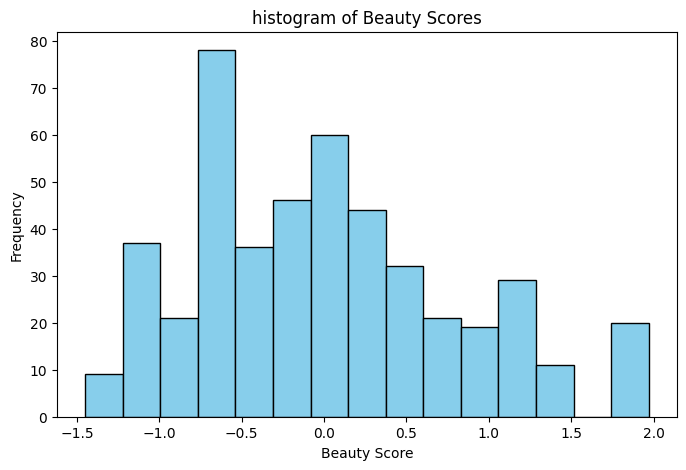

In [6]:
plt.figure(figsize=(8,5))
plt.hist(df['beauty'], bins=15, color='skyblue', edgecolor='black')
plt.xlabel('Beauty Score')
plt.ylabel('Frequency')
plt.title('histogram of Beauty Scores')
plt.show()

The beauty variable is a standardized score ranging roughly from -1.45 to 1.97. Most instructors cluster near the average -1 to 0.5. Overall the beauty score shows  moderately irregular distribution

# Q5: Beauty by gender

In [7]:
df.groupby('gender')['beauty'].agg(['mean','std']).round(2)

,mean,std
gender,,
female,0.12,0.82
male,-0.08,0.76


Yes, it differs slightly ,female instructors have a higher average beauty score (0.12) than male instructors (-0.08), a difference of about 0.20 on the standardized scale.Std dev is similar between the two groups, so the difference is mainly in the average level.

# Q6: Tenure by gender

In [8]:
df["tenure"].value_counts()

,count
tenure,
yes,361
no,102


In [9]:
df.groupby("gender")["tenure"].value_counts()

gender  tenure
female  yes       145
        no         50
male    yes       216
        no         52
Name: count, dtype: int64

In [10]:
tenure_per = (
    df.groupby("gender")["tenure"]
    .apply(lambda x: (x=="yes").mean()*100)
)
tenure_per.round(2)

,tenure
gender,
female,74.36
male,80.60


In [11]:
tenure_per = (
    df.groupby("gender")["tenure"]
    .apply(lambda x: (x=="no").mean()*100)
)
tenure_per.round(2)

tenure     no    yes
gender              
female  25.64  74.36
male    19.40  80.60


The percentage of female instructors who are tenured is 74.36%, while the percentage of male instructors who are tenured is 80.60%.
Therefore, the proportion of instructors with tenure differs by gender in this sample, with male instructors having a higher percentage of tenured instructors than female instructors.